<a href="https://colab.research.google.com/github/KarenInfanta/openfda-adverse-event-analysis/blob/main/notebooks/03_exploratory_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/openfda-project')
DATA = ROOT / 'data'
FIG = ROOT / 'outputs/figures'
TAB = ROOT / 'outputs/tables'
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')

print(sorted(p.name for p in (DATA / 'processed').iterdir()))

Mounted at /content/drive
['daily_report_counts_2021_2025.csv', 'drugs_clean.csv', 'drugs_extracted.csv', 'reactions_clean.csv', 'reactions_extracted.csv', 'report_drugs.csv', 'report_reactions.csv', 'reports_clean.csv', 'reports_extracted.csv']


Loaded cached counts from Drive.

Date range: 2021-01-01 to 2025-12-31
Days with data: 1826 of 1826
January 2024 total: 106,399 (our earlier check: 106,399)

Per-year totals:
        total  days_with_data
date                         
2021  1566148             365
2022  1523664             365
2023  1368572             365
2024  1319106             366
2025  1307769             365

Months: 60
Lowest month:  2024-06 99,229
Highest month: 2021-07 163,162
Median month:  115,612

Quarterly counts:
date
2021-Q1    387835
2021-Q2    396786
2021-Q3    421995
2021-Q4    359532
2022-Q1    389745
2022-Q2    365979
2022-Q3    366319
2022-Q4    401621
2023-Q1    356665
2023-Q2    335634
2023-Q3    344102
2023-Q4    332171
2024-Q1    325806
2024-Q2    325446
2024-Q3    332487
2024-Q4    335367
2025-Q1    325255
2025-Q2    323832
2025-Q3    339468
2025-Q4    319214
Name: reports, dtype: int64


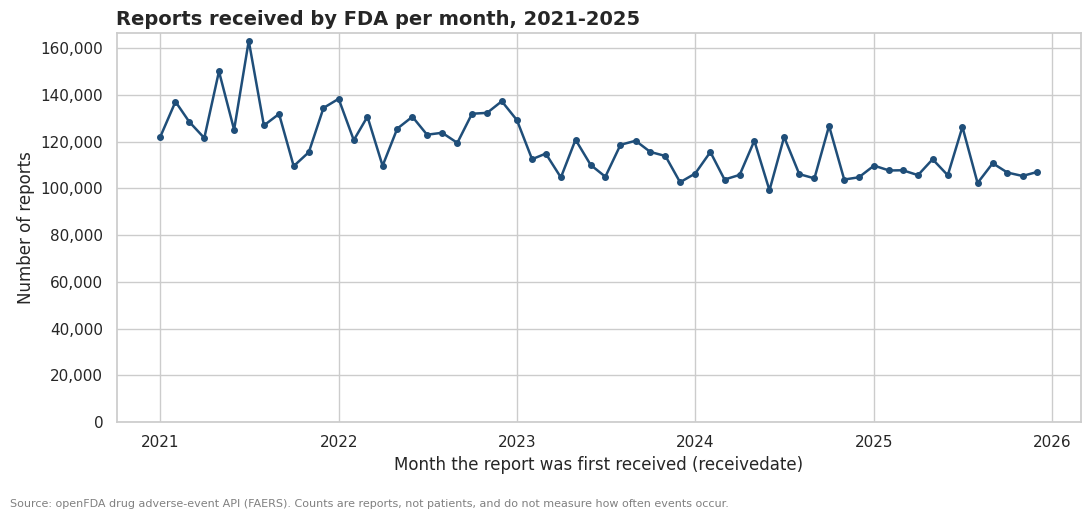

In [2]:
BASE_URL = 'https://api.fda.gov/drug/event.json'
CACHE = DATA / 'processed/daily_report_counts_2021_2025.csv'


def get_daily_counts(start, end, max_retries=5):
    """True number of reports per receive date, aggregated by the API itself.
    Note: no 'limit' parameter. The default already returns every day,
    and limit=1000 was rejected with API_KEY_MISSING."""
    params = {'search': f'receivedate:[{start} TO {end}]', 'count': 'receivedate'}
    for attempt in range(1, max_retries + 1):
        try:
            r = requests.get(BASE_URL, params=params, timeout=60)
        except requests.exceptions.RequestException as e:
            print(f'  network error ({e}); retry {attempt}/{max_retries}')
            time.sleep(2 ** attempt)
            continue
        if r.status_code == 200:
            return r.json().get('results', [])
        if r.status_code == 404:
            return []
        if r.status_code in (429, 500, 502, 503, 504):
            print(f'  HTTP {r.status_code}; retry {attempt}/{max_retries}')
            time.sleep(2 ** attempt)
            continue
        print('  request rejected:', r.status_code, r.text[:300])
        r.raise_for_status()
    raise RuntimeError(f'Gave up on {start}-{end}')


if CACHE.exists():
    daily = pd.read_csv(CACHE, parse_dates=['date'])
    print('Loaded cached counts from Drive.')
else:
    rows = []
    for year in range(2021, 2026):
        res = get_daily_counts(f'{year}0101', f'{year}1231')
        print(year, '->', len(res), 'dates returned')
        if len(res) >= 1000:
            print('  WARNING: result may be truncated')
        rows.extend(res)
        time.sleep(1)
    raw_counts = pd.DataFrame(rows)
    key = 'time' if 'time' in raw_counts.columns else 'term'
    daily = pd.DataFrame({'date': pd.to_datetime(raw_counts[key], format='%Y%m%d'),
                          'reports': raw_counts['count']}).sort_values('date')
    daily.to_csv(CACHE, index=False)

# ---------- Checks ----------
assert not daily['date'].duplicated().any()
span = (daily['date'].max() - daily['date'].min()).days + 1
print('\nDate range:', daily['date'].min().date(), 'to', daily['date'].max().date())
print('Days with data:', len(daily), 'of', span)
jan24 = daily[(daily['date'] >= '2024-01-01') & (daily['date'] <= '2024-01-31')]['reports'].sum()
print('January 2024 total:', f'{jan24:,}', '(our earlier check: 106,399)')
print('\nPer-year totals:')
print(daily.groupby(daily['date'].dt.year)['reports'].agg(total='sum', days_with_data='count'))

# ---------- Monthly and quarterly tables ----------
series = daily.set_index('date')['reports']
monthly = series.resample('MS').sum()
quarterly = series.resample('QS').sum()
monthly.to_csv(TAB / 'monthly_report_counts.csv', header=['reports'])
quarterly.to_csv(TAB / 'quarterly_report_counts.csv', header=['reports'])

print('\nMonths:', len(monthly))
print('Lowest month: ', monthly.idxmin().strftime('%Y-%m'), f'{monthly.min():,}')
print('Highest month:', monthly.idxmax().strftime('%Y-%m'), f'{monthly.max():,}')
print('Median month: ', f'{int(monthly.median()):,}')
print('\nQuarterly counts:')
print(quarterly.rename(lambda d: f'{d.year}-Q{d.quarter}'))

# ---------- Chart ----------
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly.values, marker='o', markersize=4,
        linewidth=1.8, color='#1f4e79')
ax.set_title('Reports received by FDA per month, 2021-2025',
             fontsize=14, weight='bold', loc='left')
ax.set_xlabel('Month the report was first received (receivedate)')
ax.set_ylabel('Number of reports')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylim(bottom=0)
fig.text(0.01, -0.03,
         'Source: openFDA drug adverse-event API (FAERS). Counts are reports, not patients, '
         'and do not measure how often events occur.', fontsize=8, color='gray')
plt.tight_layout()
fig.savefig(FIG / '01_monthly_report_trend.png', dpi=200, bbox_inches='tight')
plt.show()

## Finding 1: Reports received per year, 2021-2025
- **Metric:** 1,566,148 reports (2021) to 1,307,769 (2025), a 16.5% decrease. Largest yearly step: 2022 to 2023 (-10.2%). 2024 to 2025: -0.9%. Monthly range: 99,229 (2024-06) to 163,162 (2021-07); median month 115,612.
- **Interpretation:** FDA received fewer reports per year over this period, and quarterly counts in 2024-2025 are roughly stable (319,214 to 339,468).
- **Business relevance:** Report volume indicates the workload and data availability for pharmacovigilance teams. It is not a safety measure.
- **Limitations:** Counts are reports by first-received date, not patients or events. They do not measure incidence, may include duplicate reports, and depend on reporting practices. The cause of the decline cannot be determined from this data. Recent months may be revised as openFDA refreshes. Daily counts are uneven: July 2021 (the highest month) includes three days (13-15 July) with 43,642 reports, 26.7% of that month's 163,162, and six of the ten busiest days in 2021-2025 fall in 2021. As a rough check, setting 2021's six busiest days to the median day (4,579) lowers 2021 by about 53,000 reports, and the 2021-2025 decline is still about 13.6%. The causes cannot be determined from this data.

Reports: 3100 | report-drug rows: 8605 | report-reaction rows: 9217
Saved figures so far: ['01_monthly_report_trend.png', '02_top10_suspect_drugs.png', '03_top10_reactions.png', '04_age_group_distribution.png', '05_sex_distribution.png', '06_report_outcome_distribution.png', '07_drug_reaction_heatmap.png']

Reports with at least one suspect drug: 3,086 of 3,100

Top 10 suspect drugs (unique reports):
                    reports  pct_of_reports_with_suspect_drug
drug_name_std                                                
LEUPROLIDE ACETATE      167                               5.4
DUPILUMAB               137                               4.4
ADALIMUMAB              131                               4.2
EVOLOCUMAB              113                               3.7
RISANKIZUMAB-RZAA       110                               3.6
CLOZAPINE                95                               3.1
UPADACITINIB             88                               2.9
FENTANYL                 79           

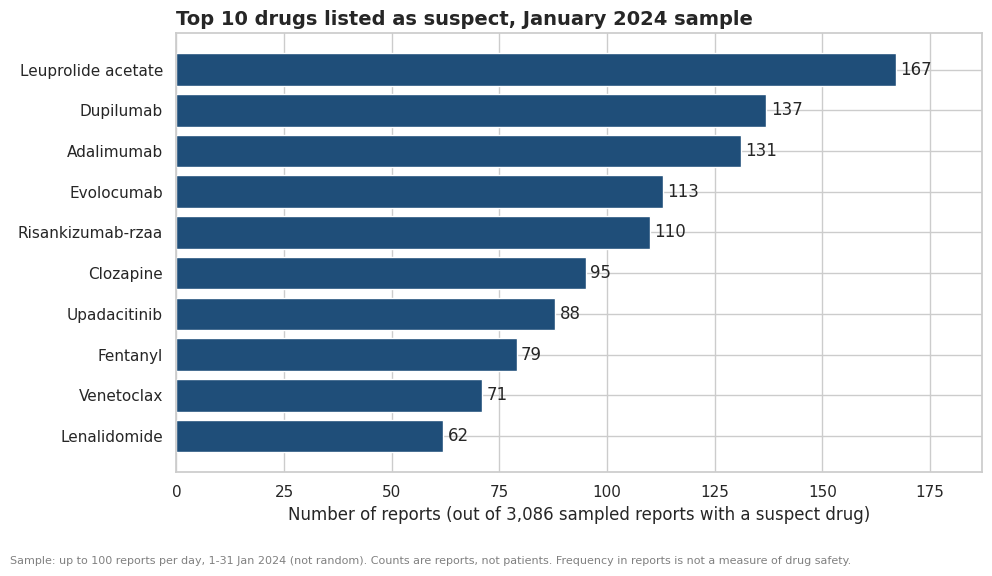

In [3]:
# ---------- Load the clean tables (dtype=str keeps codes as text) ----------
reports = pd.read_csv(DATA / 'processed/reports_clean.csv', dtype=str)
report_drugs = pd.read_csv(DATA / 'processed/report_drugs.csv', dtype=str)
report_reactions = pd.read_csv(DATA / 'processed/report_reactions.csv', dtype=str)

for col in ['is_suspect', 'is_concomitant', 'is_interacting']:
    report_drugs[col] = report_drugs[col].str.lower().eq('true')
report_reactions['any_fatal'] = report_reactions['any_fatal'].str.lower().eq('true')
reports['version_int'] = pd.to_numeric(reports['safetyreportversion']).astype(int)
reports['n_reportduplicate'] = pd.to_numeric(reports['n_reportduplicate']).astype(int)

N_REPORTS = reports['safetyreportid'].nunique()
print('Reports:', N_REPORTS, '| report-drug rows:', len(report_drugs),
      '| report-reaction rows:', len(report_reactions))
assert report_drugs['safetyreportid'].isin(reports['safetyreportid']).all()
print('Saved figures so far:', sorted(p.name for p in FIG.iterdir()))

# ---------- Top 10 suspect drugs, counted in unique reports ----------
suspect = report_drugs[report_drugs['is_suspect']]
n_susp = suspect['safetyreportid'].nunique()
print(f'\nReports with at least one suspect drug: {n_susp:,} of {N_REPORTS:,}')


def suspect_counts(ids=None):
    s = suspect if ids is None else suspect[suspect['safetyreportid'].isin(ids)]
    return s.groupby('drug_name_std')['safetyreportid'].nunique().sort_values(ascending=False)


all_counts = suspect_counts()
top10 = all_counts.head(10)
table = pd.DataFrame({'reports': top10,
                      'pct_of_reports_with_suspect_drug': (top10 / n_susp * 100).round(1)})
table.to_csv(TAB / 'top10_suspect_drugs.csv')
print('\nTop 10 suspect drugs (unique reports):')
print(table)

# ---------- Sensitivity check: does the list change if we drop follow-ups or flagged reports? ----------
ids_v1 = set(reports.loc[reports['version_int'] == 1, 'safetyreportid'])
ids_nodup = set(reports.loc[reports['n_reportduplicate'] == 0, 'safetyreportid'])
scen = {'All reports': all_counts,
        'Version 1 only': suspect_counts(ids_v1),
        'No duplicate identifiers': suspect_counts(ids_nodup)}
print('\nReports in each scenario: all =', N_REPORTS,
      '| version 1 =', len(ids_v1), '| no duplicate identifiers =', len(ids_nodup))

comp = pd.DataFrame({name: [f'{d} ({c})' for d, c in s.head(10).items()]
                     for name, s in scen.items()})
comp.index = range(1, 11)
print('\nTop 10 under each scenario (unique reports in brackets):')
print(comp.to_string())
base = set(all_counts.head(10).index)
print('\nOverlap with the all-reports top 10:',
      {name: len(set(s.head(10).index) & base) for name, s in scen.items()})

# ---------- Chart ----------
plot_df = top10.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh([d.capitalize() for d in plot_df.index], plot_df.values, color='#1f4e79')
ax.bar_label(bars, padding=3)
ax.set_title('Top 10 drugs listed as suspect, January 2024 sample',
             fontsize=14, weight='bold', loc='left')
ax.set_xlabel(f'Number of reports (out of {n_susp:,} sampled reports with a suspect drug)')
ax.set_xlim(0, plot_df.max() * 1.12)
fig.text(0.01, -0.04,
         'Sample: up to 100 reports per day, 1-31 Jan 2024 (not random). Counts are reports, not '
         'patients. Frequency in reports is not a measure of drug safety.',
         fontsize=8, color='gray')
plt.tight_layout()
fig.savefig(FIG / '02_top10_suspect_drugs.png', dpi=200, bbox_inches='tight')
plt.show()

Reports with at least one reaction term: 3100

Top 10 reaction terms (unique reports):
                              reports  pct_of_all_reports  product_use_term
reaction_pt                                                                
DEATH                             219                 7.1             False
OFF LABEL USE                     211                 6.8              True
DRUG INEFFECTIVE                  154                 5.0              True
FATIGUE                           107                 3.5             False
PRODUCT DOSE OMISSION ISSUE       103                 3.3              True
DRUG DOSE OMISSION BY DEVICE       82                 2.6              True
DRUG ABUSE                         80                 2.6             False
DIARRHOEA                          79                 2.5             False
FALL                               75                 2.4             False
DYSPNOEA                           73                 2.4             False



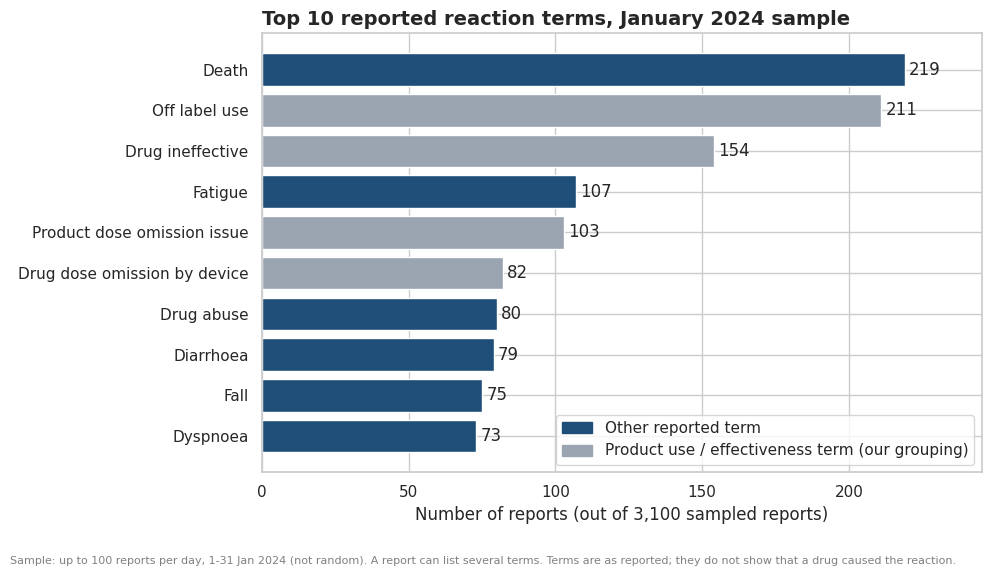

In [4]:
from matplotlib.patches import Patch

print('Reports with at least one reaction term:', report_reactions['safetyreportid'].nunique())

rx_counts = (report_reactions.groupby('reaction_pt')['safetyreportid']
             .nunique().sort_values(ascending=False))
top10_rx = rx_counts.head(10)

# Our own grouping: terms about product use or effectiveness rather than a clinical symptom
PRODUCT_USE = {'OFF LABEL USE', 'DRUG INEFFECTIVE',
               'PRODUCT DOSE OMISSION ISSUE', 'DRUG DOSE OMISSION BY DEVICE'}

table_rx = pd.DataFrame({'reports': top10_rx,
                         'pct_of_all_reports': (top10_rx / N_REPORTS * 100).round(1),
                         'product_use_term': top10_rx.index.isin(PRODUCT_USE)})
table_rx.to_csv(TAB / 'top10_reactions.csv')
print('\nTop 10 reaction terms (unique reports):')
print(table_rx)

excl = rx_counts[~rx_counts.index.isin(PRODUCT_USE)].head(10)
print('\nTop 10 after setting aside the product-use terms (our own grouping):')
print(excl)

# The DEATH reaction term and the death seriousness flag are different fields
death_term = set(report_reactions.loc[report_reactions['reaction_pt'] == 'DEATH', 'safetyreportid'])
death_flag = set(reports.loc[reports['report_outcome'] == 'Death', 'safetyreportid'])
print('\nReports with reaction term DEATH:', len(death_term))
print('Reports with the death seriousness flag:', len(death_flag))
print('Reports with both:', len(death_term & death_flag))

# ---------- Chart ----------
plot_rx = top10_rx.iloc[::-1]
colors = ['#9aa5b1' if t in PRODUCT_USE else '#1f4e79' for t in plot_rx.index]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh([t.capitalize() for t in plot_rx.index], plot_rx.values, color=colors)
ax.bar_label(bars, padding=3)
ax.set_title('Top 10 reported reaction terms, January 2024 sample',
             fontsize=14, weight='bold', loc='left')
ax.set_xlabel(f'Number of reports (out of {N_REPORTS:,} sampled reports)')
ax.set_xlim(0, plot_rx.max() * 1.12)
ax.legend(handles=[Patch(color='#1f4e79', label='Other reported term'),
                   Patch(color='#9aa5b1', label='Product use / effectiveness term (our grouping)')],
          loc='lower right', frameon=True)
fig.text(0.01, -0.04,
         'Sample: up to 100 reports per day, 1-31 Jan 2024 (not random). A report can list several '
         'terms. Terms are as reported; they do not show that a drug caused the reaction.',
         fontsize=8, color='gray')
plt.tight_layout()
fig.savefig(FIG / '03_top10_reactions.png', dpi=200, bbox_inches='tight')
plt.show()

In [5]:
top_days = daily.sort_values('reports', ascending=False).head(10)
print('10 busiest days:')
print(top_days.assign(weekday=top_days['date'].dt.day_name()).to_string(index=False))
print('\nMedian daily count:', int(daily['reports'].median()))

jul21 = daily[(daily['date'] >= '2021-07-01') & (daily['date'] <= '2021-07-31')]
print('\nJuly 2021: five busiest days')
print(jul21.nlargest(5, 'reports').to_string(index=False))
print('July 2021 median day:', int(jul21['reports'].median()))

10 busiest days:
      date  reports   weekday
2021-07-13    16711   Tuesday
2021-07-14    15200 Wednesday
2021-02-01    12860    Monday
2021-02-03    12287 Wednesday
2024-10-18    12281    Friday
2021-05-28    11853    Friday
2021-07-15    11731  Thursday
2022-01-31    11008    Monday
2022-01-03    10034    Monday
2022-03-02     9317 Wednesday

Median daily count: 4579

July 2021: five busiest days
      date  reports
2021-07-13    16711
2021-07-14    15200
2021-07-15    11731
2021-07-28     9152
2021-07-29     9151
July 2021 median day: 4855


## Finding 2: Drugs most often listed as suspect (January 2024 sample)
- **Metric:** Leuprolide acetate was listed as suspect in 167 of 3,086 sampled reports with a suspect drug (5.4%), followed by dupilumab (137), adalimumab (131), evolocumab (113) and risankizumab-rzaa (110). Seven of the top ten appeared in the top ten under all three scenarios tested (all reports; version 1 only; no duplicate identifiers).
- **Interpretation:** These drugs account for the most sampled reports in which they are named as suspect. Rankings shifted for some drugs when follow-up or duplicate-flagged reports were excluded.  Rankings shifted when follow-up reports (28.9% of reports) or reports listing duplicate identifiers (29.5%) were excluded. The shifts follow how each drug's reports are submitted: 97.1% of dupilumab and 97.3% of evolocumab reports list duplicate identifiers, versus 0.9% to 6.8% for risankizumab-rzaa, leuprolide acetate, clozapine, fentanyl and upadacitinib, and 50.4% of evolocumab reports are follow-up versions. Excluding reports with duplicate identifiers is therefore not deduplication; it removes most of those two drugs' reports.
- **Business relevance:** Shows where report volume is concentrated, which helps prioritise data-quality work such as drug-name standardisation.
- **Limitations:** Sample of up to 100 reports per day (not random). Counts are reports, not patients. Frequency depends on how widely a drug is used and how reports are submitted, so it says nothing about risk or safety. Drug names are standardised imperfectly.

## Finding 3: Reaction terms most often reported (January 2024 sample)
- **Metric:** DEATH appeared in 219 of 3,100 sampled reports (7.1%), off label use in 211 (6.8%), drug ineffective in 154 (5.0%) and fatigue in 107 (3.5%). Four of the top ten terms describe product use or effectiveness (our own grouping). All 219 reports with the DEATH term also carry the death seriousness flag, which appears in 468 reports.
- **Interpretation:** Many frequently reported terms describe how a product was used or whether it worked, not a clinical symptom.
- **Business relevance:** Reaction summaries should separate product-use terms from clinical terms before review.
- **Limitations:** A report can list several terms. Terms do not show that a drug caused the reaction. The DEATH term and the death flag are different fields and are not added together. This sample cannot give how often any reaction occurs.

In [6]:
print('Saved figures:', sorted(p.name for p in FIG.iterdir()))

# For each top-10 suspect drug: what share of its reports are follow-ups or list duplicate identifiers?
flags_df = reports[['safetyreportid', 'version_int', 'n_reportduplicate']].copy()
flags_df['is_followup'] = flags_df['version_int'] > 1
flags_df['has_dup_ids'] = flags_df['n_reportduplicate'] > 0

sus = (suspect[suspect['drug_name_std'].isin(top10.index)]
       [['safetyreportid', 'drug_name_std']].drop_duplicates()
       .merge(flags_df, on='safetyreportid', how='left', validate='many_to_one'))

shares = (sus.groupby('drug_name_std')
          .agg(reports=('safetyreportid', 'nunique'),
               pct_followup=('is_followup', 'mean'),
               pct_with_duplicate_ids=('has_dup_ids', 'mean'))
          .sort_values('reports', ascending=False))
shares[['pct_followup', 'pct_with_duplicate_ids']] *= 100
shares = shares.round(1)
print('\nShare of each top-10 drug\'s reports that are follow-ups / list duplicate identifiers:')
print(shares)

overall = flags_df[['is_followup', 'has_dup_ids']].mean().mul(100).round(1)
print('\nAll reports: % follow-up =', overall['is_followup'],
      '| % with duplicate identifiers =', overall['has_dup_ids'])

comp.to_csv(TAB / 'top10_drugs_sensitivity.csv', index_label='rank')
shares.to_csv(TAB / 'top10_drugs_followup_duplicate_shares.csv')

Saved figures: ['01_monthly_report_trend.png', '02_top10_suspect_drugs.png', '03_top10_reactions.png', '04_age_group_distribution.png', '05_sex_distribution.png', '06_report_outcome_distribution.png', '07_drug_reaction_heatmap.png']

Share of each top-10 drug's reports that are follow-ups / list duplicate identifiers:
                    reports  pct_followup  pct_with_duplicate_ids
drug_name_std                                                    
LEUPROLIDE ACETATE      167          43.1                     1.8
DUPILUMAB               137          33.6                    97.1
ADALIMUMAB              131          30.5                    22.1
EVOLOCUMAB              113          50.4                    97.3
RISANKIZUMAB-RZAA       110          35.5                     0.9
CLOZAPINE                95           4.2                     2.1
UPADACITINIB             88          26.1                     6.8
FENTANYL                 79           8.9                     3.8
VENETOCLAX          

Reports with a recorded age: 1,824 of 3,100 | median age: 61


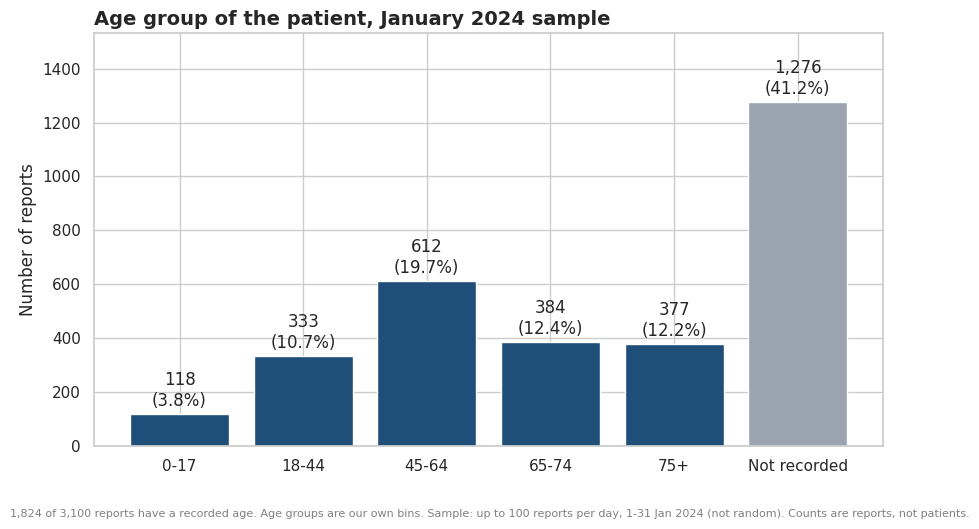


Sex:
 sex
Female          1399
Male            1260
Not recorded     441
Name: count, dtype: int64


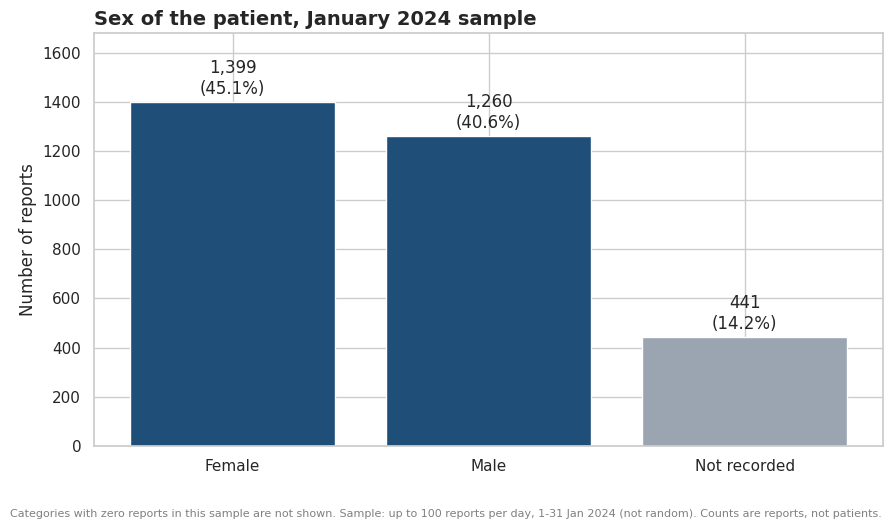


Report outcome (highest category per report):
 report_outcome
Death                  468
Life-threatening        53
Hospitalization        537
Disability              17
Congenital anomaly       4
Other serious          829
Not serious           1192
Name: count, dtype: int64


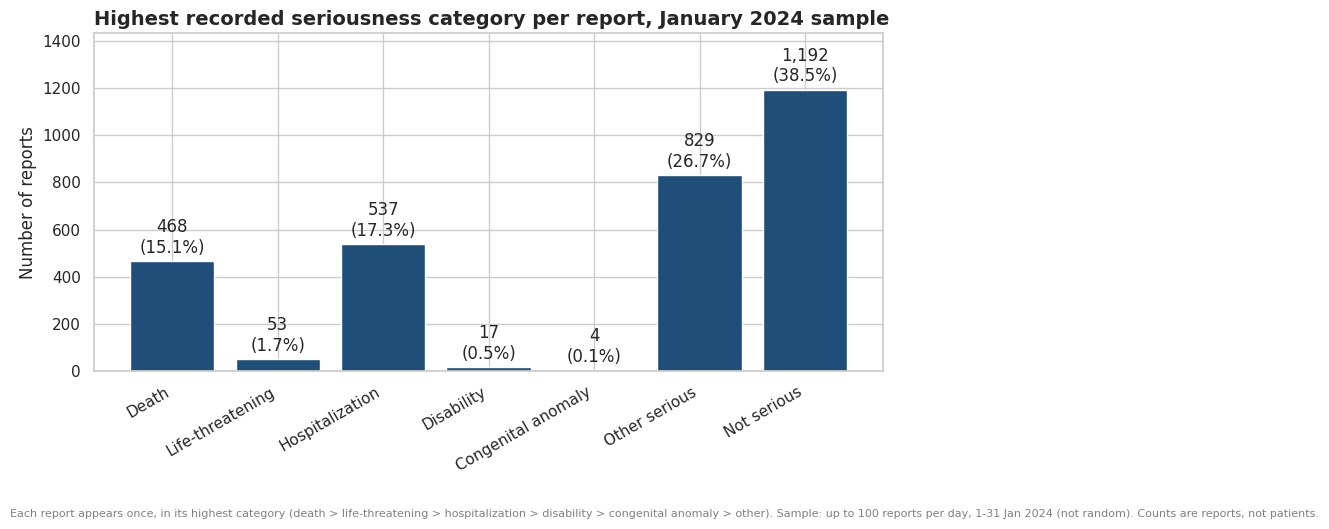


Reports carrying each flag (a report can carry several, so these add up to more than the number of serious reports):
Death                  468
Life-threatening        72
Hospitalization        682
Disability              36
Congenital anomaly       7
Other serious         1333
dtype: int64


In [7]:
reports['age_years'] = pd.to_numeric(reports['age_years'])
MUTED = {'Not recorded', 'Unknown'}


def count_chart(counts, title, ylabel, note, fname, rotate=0):
    """Bar chart with count and share labels; grey bars = unknown/not recorded."""
    colors = ['#9aa5b1' if c in MUTED else '#1f4e79' for c in counts.index]
    total = counts.sum()
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(counts.index.astype(str), counts.values, color=colors)
    ax.bar_label(bars, labels=[f'{v:,}\n({v / total:.1%})' for v in counts.values], padding=3)
    ax.set_title(title, fontsize=14, weight='bold', loc='left')
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, counts.max() * 1.2)
    plt.xticks(rotation=rotate, ha='right' if rotate else 'center')
    fig.text(0.01, -0.05, note, fontsize=8, color='gray')
    plt.tight_layout()
    fig.savefig(FIG / fname, dpi=200, bbox_inches='tight')
    plt.show()


SAMPLE_NOTE = 'Sample: up to 100 reports per day, 1-31 Jan 2024 (not random). Counts are reports, not patients.'

# ---------- Age ----------
age_order = ['0-17', '18-44', '45-64', '65-74', '75+', 'Not recorded']
age_counts = reports['age_group'].value_counts().reindex(age_order).fillna(0).astype(int)
n_age = int(reports['age_years'].notna().sum())
print(f'Reports with a recorded age: {n_age:,} of {N_REPORTS:,} | median age: {reports["age_years"].median():.0f}')
age_counts.to_csv(TAB / 'age_group_counts.csv', header=['reports'])
count_chart(age_counts, 'Age group of the patient, January 2024 sample', 'Number of reports',
            f'{n_age:,} of {N_REPORTS:,} reports have a recorded age. Age groups are our own bins. ' + SAMPLE_NOTE,
            '04_age_group_distribution.png')

# ---------- Sex ----------
sex_order = ['Female', 'Male', 'Unknown', 'Not recorded']
sex_counts = reports['sex'].value_counts().reindex(sex_order).fillna(0).astype(int)
sex_counts = sex_counts[sex_counts > 0]
print('\nSex:\n', sex_counts)
sex_counts.to_csv(TAB / 'sex_counts.csv', header=['reports'])
count_chart(sex_counts, 'Sex of the patient, January 2024 sample', 'Number of reports',
            'Categories with zero reports in this sample are not shown. ' + SAMPLE_NOTE,
            '05_sex_distribution.png')

# ---------- Report outcome (one category per report) ----------
out_order = ['Death', 'Life-threatening', 'Hospitalization', 'Disability', 'Congenital anomaly',
             'Other serious', 'Serious (type not specified)', 'Not serious', 'Not recorded']
out_counts = reports['report_outcome'].value_counts().reindex(out_order).fillna(0).astype(int)
out_counts = out_counts[out_counts > 0]
print('\nReport outcome (highest category per report):\n', out_counts)
out_counts.to_csv(TAB / 'report_outcome_counts.csv', header=['reports'])
count_chart(out_counts, 'Highest recorded seriousness category per report, January 2024 sample',
            'Number of reports',
            'Each report appears once, in its highest category (death > life-threatening > hospitalization > '
            'disability > congenital anomaly > other). ' + SAMPLE_NOTE,
            '06_report_outcome_distribution.png', rotate=30)

# ---------- Every flag counted separately (reports can appear in several) ----------
flag_cols = {'seriousnessdeath': 'Death', 'seriousnesslifethreatening': 'Life-threatening',
             'seriousnesshospitalization': 'Hospitalization', 'seriousnessdisabling': 'Disability',
             'seriousnesscongenitalanomali': 'Congenital anomaly', 'seriousnessother': 'Other serious'}
flag_counts = pd.Series({lab: int((reports[c] == '1').sum()) for c, lab in flag_cols.items()})
print('\nReports carrying each flag (a report can carry several, so these add up to more than the number of serious reports):')
print(flag_counts)
flag_counts.to_csv(TAB / 'seriousness_flag_counts.csv', header=['reports'])

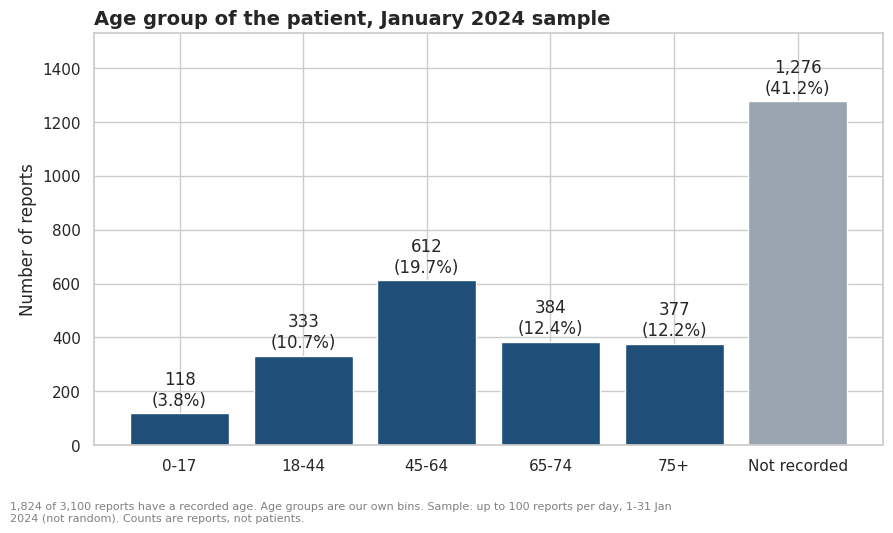

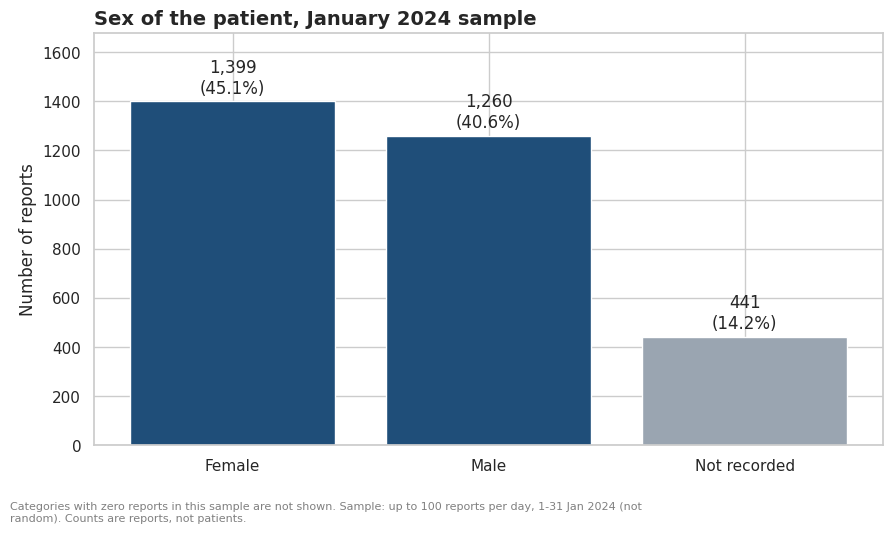

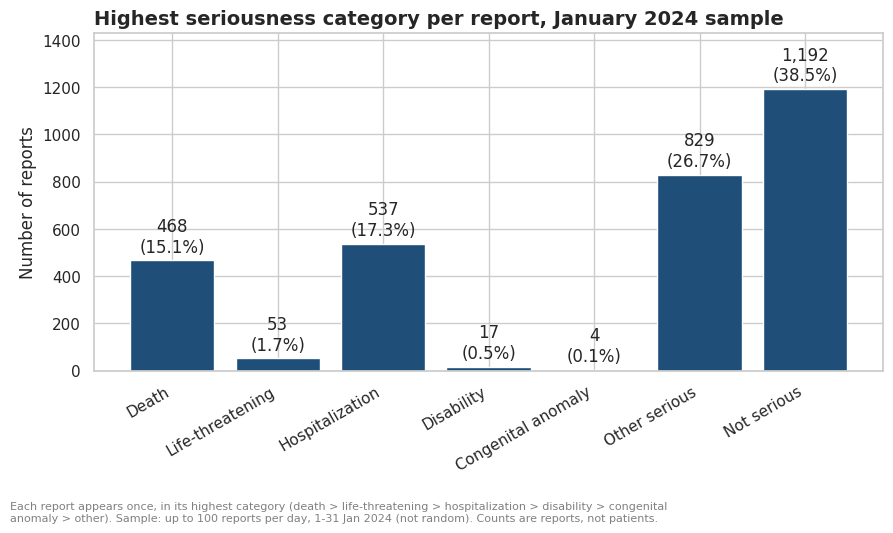

In [8]:
import textwrap


def count_chart(counts, title, ylabel, note, fname, rotate=0):
    """Bar chart with count and share labels; grey bars = unknown/not recorded.
    The footnote is wrapped so it can never make the saved image wider than the plot."""
    colors = ['#9aa5b1' if c in MUTED else '#1f4e79' for c in counts.index]
    total = counts.sum()
    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(counts.index.astype(str), counts.values, color=colors)
    ax.bar_label(bars, labels=[f'{v:,}\n({v / total:.1%})' for v in counts.values], padding=3)
    ax.set_title(title, fontsize=14, weight='bold', loc='left')
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, counts.max() * 1.2)
    plt.xticks(rotation=rotate, ha='right' if rotate else 'center')
    fig.text(0.01, -0.02, textwrap.fill(note, width=120), fontsize=8, color='gray', va='top')
    plt.tight_layout()
    fig.savefig(FIG / fname, dpi=200, bbox_inches='tight')
    plt.show()


count_chart(age_counts, 'Age group of the patient, January 2024 sample', 'Number of reports',
            f'{n_age:,} of {N_REPORTS:,} reports have a recorded age. Age groups are our own bins. ' + SAMPLE_NOTE,
            '04_age_group_distribution.png')
count_chart(sex_counts, 'Sex of the patient, January 2024 sample', 'Number of reports',
            'Categories with zero reports in this sample are not shown. ' + SAMPLE_NOTE,
            '05_sex_distribution.png')
count_chart(out_counts, 'Highest seriousness category per report, January 2024 sample',
            'Number of reports',
            'Each report appears once, in its highest category (death > life-threatening > hospitalization > '
            'disability > congenital anomaly > other). ' + SAMPLE_NOTE,
            '06_report_outcome_distribution.png', rotate=30)

## Finding 4: Age and sex recorded in reports (January 2024 sample)
- **Metric:** 1,824 of 3,100 reports (58.8%) have a recorded age (median 61). Among them, 45-64 is the largest group (612, 33.6%) and 65+ accounts for 761 (41.7%); 0-17 is 118 (6.5%). Sex is recorded in 2,659 reports (85.8%): 1,399 female and 1,260 male (52.6% and 47.4% of reports with a recorded sex).
- **Interpretation:** Among reports that include demographics, middle-aged and older patients are most common, and the two sexes are close in number.
- **Business relevance:** Age is missing in 41.2% of reports and sex in 14.2%, so demographic breakdowns cover only part of the data and need their denominators stated.
- **Limitations:** Shares describe who the reports are about, not who is at greater risk. They depend on who uses each drug and who reports. Age groups are our own bins. Missing values are not random.

## Finding 5: Seriousness recorded in reports (January 2024 sample)
- **Metric:** 1,908 of 3,100 reports (61.5%) are flagged serious. Highest category per report: other serious 829 (26.7%), hospitalization 537 (17.3%), death 468 (15.1%), life-threatening 53 (1.7%), disability 17, congenital anomaly 4. Counting every flag separately gives 2,598 flags on those 1,908 reports; 571 reports carry two or more flags.
- **Interpretation:** Serious reports are the majority of this sample, and "other serious" is the most common serious category.
- **Business relevance:** Choosing between one category per report and every flag changes the counts, so reports must state which they use.
- **Limitations:** Shares are not rates and do not show how often events occur or that a drug caused them. Reporting rules treat serious events differently, so the serious share is not representative of all events. The death flag (468 reports) and the DEATH reaction term (219 reports) are different fields. The sample is not random.

Reports where at least one top-10 drug is suspect: 1,042
...of which two or more top-10 drugs are suspect: 9 (these reports appear in more than one column)

Reports per drug (denominator):
drug_name_std
LEUPROLIDE ACETATE    167
DUPILUMAB             137
ADALIMUMAB            131
EVOLOCUMAB            113
RISANKIZUMAB-RZAA     110
CLOZAPINE              95
UPADACITINIB           88
FENTANYL               79
VENETOCLAX             71
LENALIDOMIDE           62
Name: safetyreportid, dtype: int64

Counts (reports):
drug_name_std                             LEUPROLIDE ACETATE  DUPILUMAB  \
reaction_pt                                                               
DRUG ABUSE                                                 0          0   
DRUG DOSE OMISSION BY DEVICE                               0          0   
DEATH                                                     14          1   
WRONG TECHNIQUE IN PRODUCT USAGE PROCESS                  10          0   
DEVICE DIFFICULT TO USE          

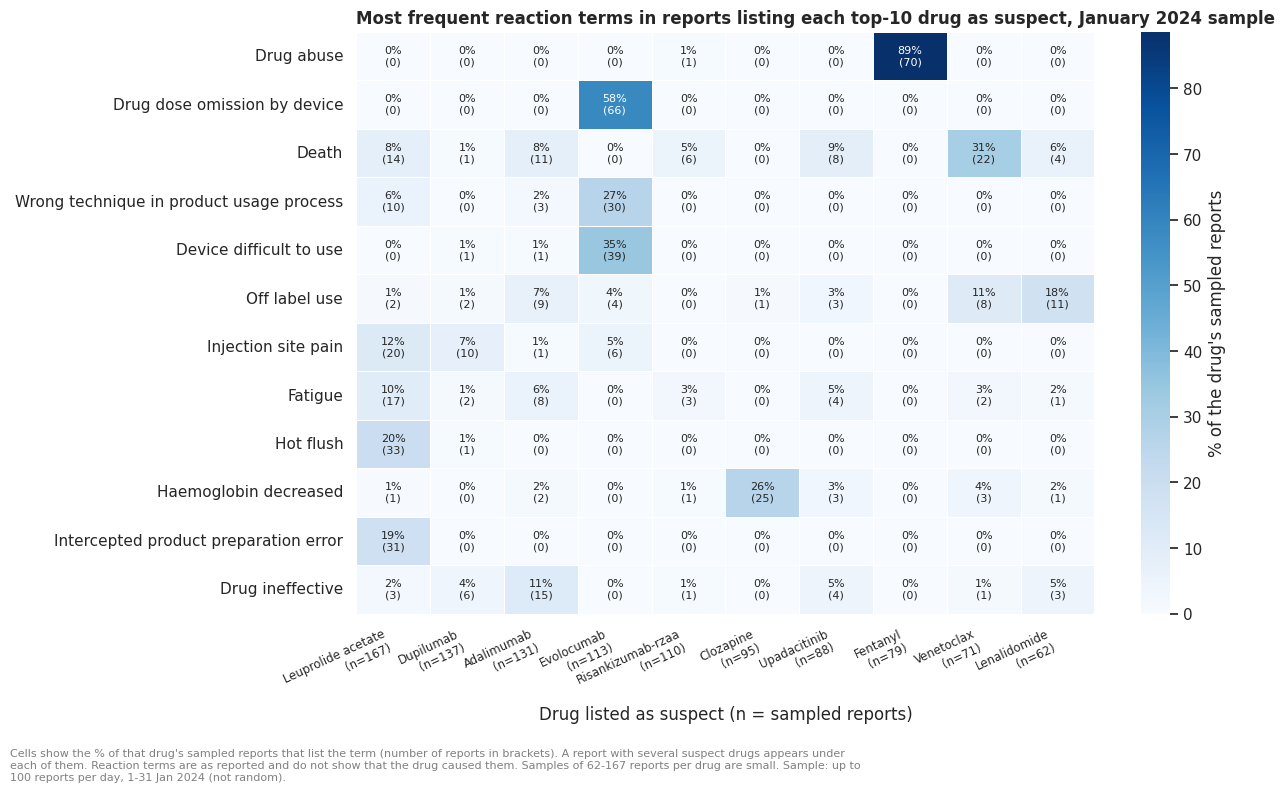

In [9]:
TOP_DRUGS = list(top10.index)   # from Cell C, most reports first

# (report, top drug) pairs, each counted once
sus_top = (suspect[suspect['drug_name_std'].isin(TOP_DRUGS)]
           [['safetyreportid', 'drug_name_std']].drop_duplicates())
denoms = sus_top.groupby('drug_name_std')['safetyreportid'].nunique().reindex(TOP_DRUGS)
assert (denoms.values == top10.values).all(), 'denominators differ from the top-10 table'

# One row per (report, drug, reaction); no row can repeat
combo = sus_top.merge(report_reactions[['safetyreportid', 'reaction_pt']], on='safetyreportid', how='inner')
assert not combo.duplicated().any()

multi = sus_top.groupby('safetyreportid').size()
print(f'Reports where at least one top-10 drug is suspect: {len(multi):,}')
print(f'...of which two or more top-10 drugs are suspect: {(multi > 1).sum():,} '
      '(these reports appear in more than one column)')

counts = (combo.groupby(['reaction_pt', 'drug_name_std'])['safetyreportid']
          .nunique().unstack(fill_value=0).reindex(columns=TOP_DRUGS, fill_value=0))

# Rows: the 12 terms found in the most reports across these drugs' reports
term_reports = combo.drop_duplicates(['safetyreportid', 'reaction_pt']).groupby('reaction_pt').size()
top_terms = term_reports.sort_values(ascending=False).head(12).index
pct = counts.loc[top_terms].div(denoms, axis=1) * 100

counts.loc[top_terms].to_csv(TAB / 'drug_reaction_counts.csv')
pct.round(1).to_csv(TAB / 'drug_reaction_percentages.csv')

print("\nReports per drug (denominator):")
print(denoms.astype(int))
print("\nCounts (reports):")
print(counts.loc[top_terms].astype(int))
print("\nPercent of each drug's reports:")
print(pct.round(0).astype(int))
print("\nTop 3 terms per drug:")
for d in TOP_DRUGS:
    t = counts[d].sort_values(ascending=False).head(3)
    print(f"{d} (n={denoms[d]}): " + '; '.join(f"{k} {v} ({v / denoms[d]:.0%})" for k, v in t.items()))

# ---------- Heatmap ----------
annot = np.array([[f'{pct.loc[t, d]:.0f}%\n({counts.loc[t, d]})' for d in TOP_DRUGS] for t in top_terms])
fig, ax = plt.subplots(figsize=(13, 7.5))
sns.heatmap(pct, annot=annot, fmt='', cmap='Blues', vmin=0, linewidths=0.5, linecolor='white',
            cbar_kws={'label': "% of the drug's sampled reports"}, ax=ax, annot_kws={'fontsize': 8})
ax.set_xticklabels([f'{d.capitalize()}\n(n={denoms[d]})' for d in TOP_DRUGS],
                   rotation=25, ha='right', fontsize=8.5)
ax.set_yticklabels([t.capitalize() for t in top_terms], rotation=0)
ax.set_xlabel('Drug listed as suspect (n = sampled reports)')
ax.set_ylabel('')
ax.set_title('Most frequent reaction terms in reports listing each top-10 drug as suspect, January 2024 sample',
             fontsize=12, weight='bold', loc='left')
note = ('Cells show the % of that drug\'s sampled reports that list the term (number of reports in brackets). '
        'A report with several suspect drugs appears under each of them. Reaction terms are as reported and '
        'do not show that the drug caused them. Samples of 62-167 reports per drug are small. '
        'Sample: up to 100 reports per day, 1-31 Jan 2024 (not random).')
fig.text(0.01, -0.01, textwrap.fill(note, width=150), fontsize=8, color='gray', va='top')
plt.tight_layout()
fig.savefig(FIG / '07_drug_reaction_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

Sum of drug denominators: 1053 | unique reports: 1042 | extra memberships: 11

Each drug's three most frequent reaction terms (unique reports):
              drug  rank                                    reaction_term  reports  drug_reports  pct_of_drug_reports
LEUPROLIDE ACETATE     1                                        HOT FLUSH       33           167                 19.8
LEUPROLIDE ACETATE     2            INTERCEPTED PRODUCT PREPARATION ERROR       31           167                 18.6
LEUPROLIDE ACETATE     3                                    SYRINGE ISSUE       30           167                 18.0
         DUPILUMAB     1                                         PRURITUS       19           137                 13.9
         DUPILUMAB     2             PRODUCT USE IN UNAPPROVED INDICATION       14           137                 10.2
         DUPILUMAB     3 INAPPROPRIATE SCHEDULE OF PRODUCT ADMINISTRATION       11           137                  8.0
        ADALIMUMAB     1      

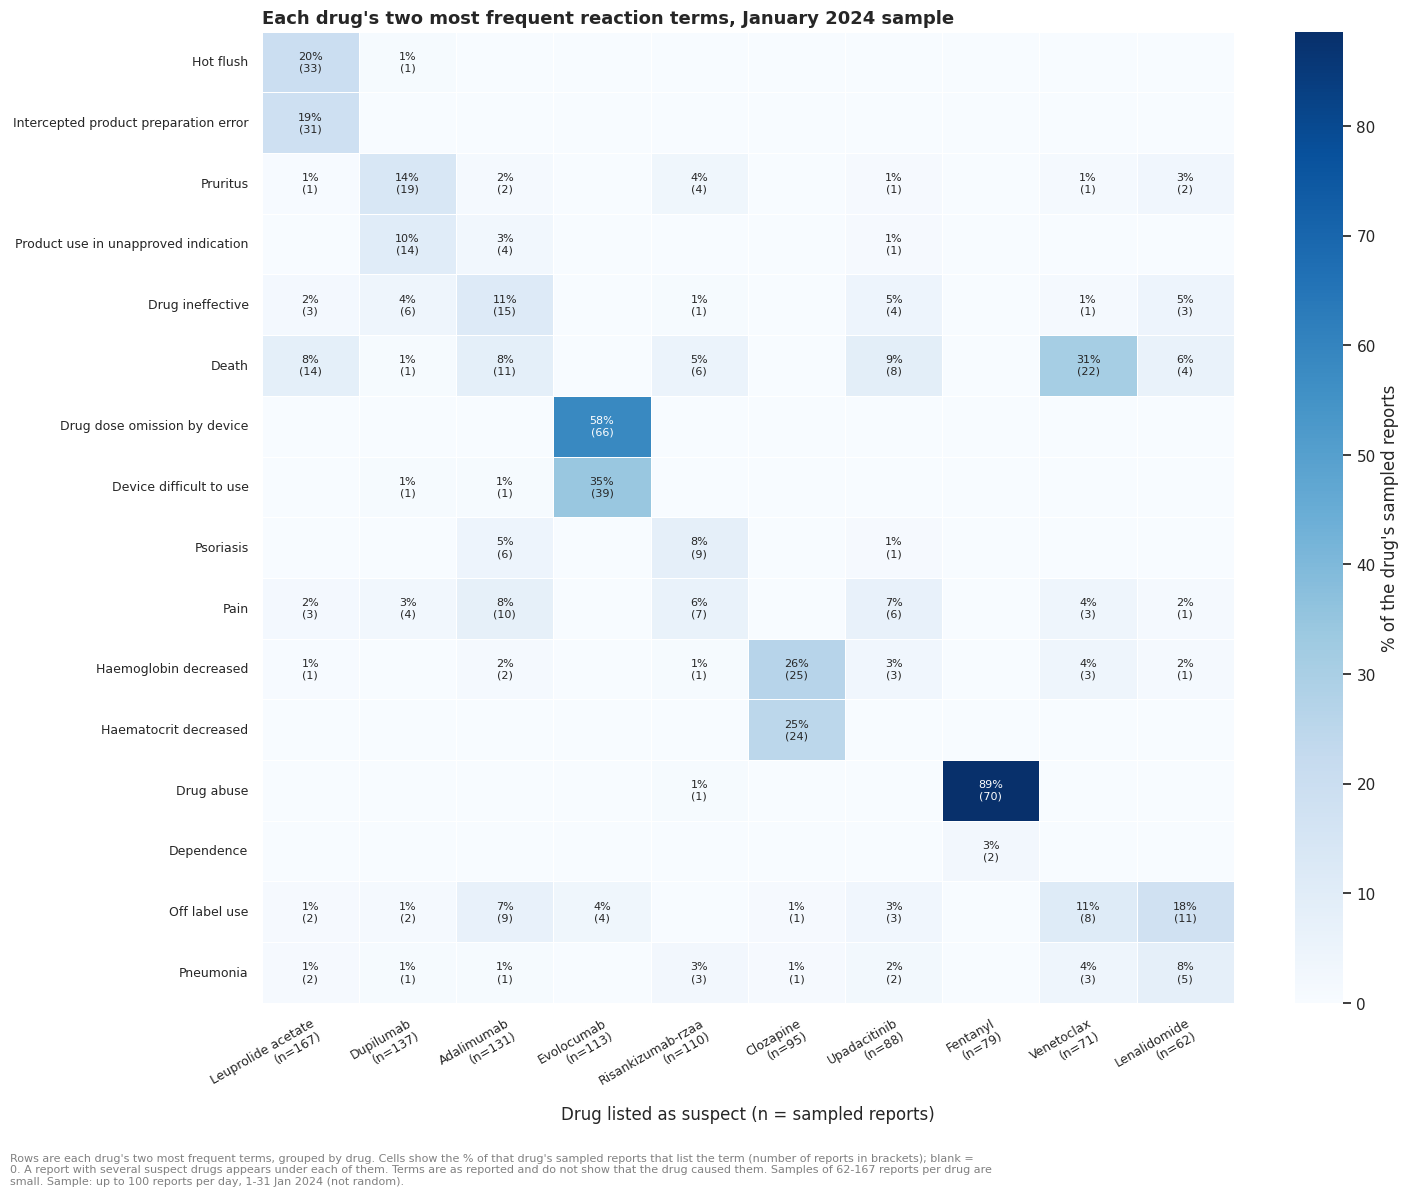

In [10]:
# ---------- Check: denominators vs unique reports ----------
print('Sum of drug denominators:', int(denoms.sum()),
      '| unique reports:', len(multi),
      '| extra memberships:', int(denoms.sum() - len(multi)))
assert multi.sum() == denoms.sum()

# ---------- Each drug's 3 most frequent terms (tidy table) ----------
top3_rows = []
for d in TOP_DRUGS:
    ranked = counts[d].sort_values(ascending=False, kind='stable').head(3)
    for rank, (term, n_rep) in enumerate(ranked.items(), start=1):
        top3_rows.append({'drug': d, 'rank': rank, 'reaction_term': term,
                          'reports': int(n_rep), 'drug_reports': int(denoms[d]),
                          'pct_of_drug_reports': round(n_rep / denoms[d] * 100, 1)})
top3 = pd.DataFrame(top3_rows)
top3.to_csv(TAB / 'top3_reaction_terms_per_drug.csv', index=False)
print('\nEach drug\'s three most frequent reaction terms (unique reports):')
print(top3.to_string(index=False))

# ---------- Heatmap rows: each drug's 2 most frequent terms, grouped by drug ----------
row_terms = []
for d in TOP_DRUGS:
    for t in counts[d].sort_values(ascending=False, kind='stable').head(2).index:
        if t not in row_terms:
            row_terms.append(t)
pct2 = counts.loc[row_terms].div(denoms, axis=1) * 100
pct2.round(1).to_csv(TAB / 'drug_reaction_percentages_top2_per_drug.csv')
print('\nHeatmap rows:', len(row_terms))

annot = np.array([[f'{pct2.loc[t, d]:.0f}%\n({counts.loc[t, d]})' if counts.loc[t, d] > 0 else ''
                   for d in TOP_DRUGS] for t in row_terms])

fig, ax = plt.subplots(figsize=(15, 0.5 * len(row_terms) + 3.5))
sns.heatmap(pct2, annot=annot, fmt='', cmap='Blues', vmin=0, linewidths=0.5, linecolor='white',
            cbar_kws={'label': "% of the drug's sampled reports"}, ax=ax, annot_kws={'fontsize': 8})
ax.set_xticklabels([f'{d.capitalize()}\n(n={denoms[d]})' for d in TOP_DRUGS],
                   rotation=30, ha='right', rotation_mode='anchor', fontsize=9)
ax.set_yticklabels([t.capitalize() for t in row_terms], rotation=0, fontsize=9)
ax.set_xlabel('Drug listed as suspect (n = sampled reports)')
ax.set_ylabel('')
ax.set_title("Each drug's two most frequent reaction terms, January 2024 sample",
             fontsize=13, weight='bold', loc='left')
note = ("Rows are each drug's two most frequent terms, grouped by drug. Cells show the % of that drug's "
        "sampled reports that list the term (number of reports in brackets); blank = 0. A report with "
        "several suspect drugs appears under each of them. Terms are as reported and do not show that the "
        "drug caused them. Samples of 62-167 reports per drug are small. "
        "Sample: up to 100 reports per day, 1-31 Jan 2024 (not random).")
fig.text(0.01, -0.01, textwrap.fill(note, width=170), fontsize=8, color='gray', va='top')
plt.tight_layout()
fig.savefig(FIG / '07_drug_reaction_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()

## Finding 6: Reaction terms reported with the ten most frequent suspect drugs (January 2024 sample)
- **Metric:** Within reports listing each drug as suspect, the most frequent terms differed sharply by drug: drug abuse in 70 of 79 fentanyl reports (89%); drug dose omission by device in 66 of 113 evolocumab reports (58%); hot flush in 33 of 167 leuprolide acetate reports (20%), alongside intercepted product preparation error (31) and syringe issue (30); haemoglobin decreased in 25 of 95 clozapine reports (26%); death in 22 of 71 venetoclax reports (31%); pruritus in 19 of 137 dupilumab reports (14%).
- **Interpretation:** The content of reports varies by drug. Some drugs' reports are dominated by product-handling or device terms, one by drug abuse, and others by clinical or laboratory terms.
- **Business relevance:** Terms should be grouped by type (product handling, misuse, clinical, laboratory) and reviewed drug by drug, not pooled across drugs.
- **Limitations:** Each percentage uses the drug's own sampled reports (62-167) as the denominator, so cells with 1-3 reports are unstable. Nine reports list two or more of the ten drugs and appear under each. Terms show what was reported, not that the drug caused it; underlying disease, other medicines and reporting practices all contribute, and the DEATH term is not the same field as the death seriousness flag. Several laboratory terms may be listed together in the same reports. Percentages must not be compared across drugs as a measure of risk. The sample is not random.Where terms tie (for example fentanyl's second term: dependence and overdose, 2 reports each), the term shown in the heatmap is arbitrary; each drug's top three are in top3_reaction_terms_per_drug.csv.


In [11]:
drugs_all = pd.read_csv(DATA / 'processed/drugs_clean.csv', dtype=str,
                        usecols=['safetyreportid', 'name_source'])
rx_all = pd.read_csv(DATA / 'processed/reactions_clean.csv', dtype=str,
                     usecols=['safetyreportid', 'reaction_outcome'])

n = N_REPORTS
flag_list = list(flag_cols)   # seriousness flag columns defined in Cell G

dq = [
    ('Reports with no recorded age',
     int(pd.to_numeric(reports['age_years'], errors='coerce').isna().sum()), n),
    ('Reports with no recorded sex', int((reports['sex'] == 'Not recorded').sum()), n),
    ('Reports with no suspect drug', n - n_susp, n),
    ('Follow-up reports (version 2 or later)', int((reports['version_int'] > 1).sum()), n),
    ('Reports listing duplicate identifiers', int((reports['n_reportduplicate'] > 0).sum()), n),
    ('Reports with no company number', int(reports['companynumb'].isna().sum()), n),
    ('Reports with two or more seriousness flags',
     int((reports[flag_list].eq('1').sum(axis=1) >= 2).sum()), n),
    ('Drug rows repeating a drug already in the same report', len(drugs_all) - len(report_drugs), len(drugs_all)),
    ('Drug names taken from reporter free text',
     int((drugs_all['name_source'] == 'reported_product_name').sum()), len(drugs_all)),
    ('Reaction rows repeating a term already in the same report', len(rx_all) - len(report_reactions), len(rx_all)),
    ('Reaction rows with outcome unknown or not recorded',
     int(rx_all['reaction_outcome'].isin(['Unknown', 'Not recorded']).sum()), len(rx_all)),
]
dq = pd.DataFrame(dq, columns=['issue', 'count', 'out_of'])
dq['pct'] = (dq['count'] / dq['out_of'] * 100).round(1)
dq.to_csv(TAB / 'data_quality_summary.csv', index=False)
print(dq.to_string(index=False))

print(f'\nSample coverage: {n:,} of 106,399 January 2024 reports = {n / 106399:.1%}')

                                                    issue  count  out_of  pct
                             Reports with no recorded age   1276    3100 41.2
                             Reports with no recorded sex    441    3100 14.2
                             Reports with no suspect drug     14    3100  0.5
                   Follow-up reports (version 2 or later)    897    3100 28.9
                    Reports listing duplicate identifiers    915    3100 29.5
                           Reports with no company number    203    3100  6.5
               Reports with two or more seriousness flags    571    3100 18.4
    Drug rows repeating a drug already in the same report   3251   11856 27.4
                 Drug names taken from reporter free text    161   11856  1.4
Reaction rows repeating a term already in the same report    118    9335  1.3
       Reaction rows with outcome unknown or not recorded   5338    9335 57.2

Sample coverage: 3,100 of 106,399 January 2024 reports = 2.9%


## Finding 7: Data-quality issues that affect the results (January 2024 sample)
- **Metric:** Age is missing in 1,276 of 3,100 reports (41.2%) and sex in 441 (14.2%). 5,338 of 9,335 reaction rows (57.2%) have an unknown or unrecorded outcome. 897 reports (28.9%) are follow-up versions, 915 (29.5%) list duplicate identifiers and 203 (6.5%) have no company number. 3,251 of 11,856 drug rows (27.4%) and 118 of 9,335 reaction rows (1.3%) repeated an item already in the same report. 571 reports (18.4%) carry two or more seriousness flags, 14 (0.5%) have no suspect drug, and 161 drug rows (1.4%) use reporter free text for the drug name. The sample covers 3,100 of 106,399 January 2024 reports (2.9%).
- **Interpretation:** Several fields are incomplete, and many reports are follow-ups or carry duplicate identifiers, so each table or chart describes only part of the reports.
- **Business relevance:** Counting unique reports, stating denominators and separating report-level from reaction-level outcomes prevent misleading summaries. Missing age, sex and outcome limit how far subgroup analysis can go.
- **Limitations:** Missing values are unlikely to be random. Duplicate identifiers do not prove duplicate cases, and the sample (up to 100 reports per day) is not random, so these percentages describe this sample only.